
# CI7340 CW1 — Dataset Understanding and Data Quality Assessment

**Group 8 | Applied Data Programming | Research Report and Visualisation**

**Team Members:**

    Aruna D Mahagamage (K2600143)
    Baba Isham Sally (K2703532)
    K G Nilanga Nayanajith Abeysekara (K2703512)
    Mihiri Thilakaratne (K2703522)

**Scope:** This notebook covers dataset understanding, the essential CW1 data-quality checks, and one shared analytical dataset. Research questions are completed separately.



## 1. Environment Setup

### 1.1 Install Required Libraries

**Aim:** Install the Python libraries required for data analysis, data cleaning, visualisation and statistical testing.

**Libraries:**
- `pandas` - Working with datasets and DataFrames.
- `numpy` - Numerical calculations.
- `matplotlib` - Creating charts and graphs.
- `seaborn` - Creating statistical visualisations.
- `scipy` - Performing statistical tests.
- `statsmodels` - Performing advanced statistical analysis.

**Option 1: Windows CMD or PowerShell**

Open Command Prompt or PowerShell and run:

```bash
py -m pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Option 2: Jupyter Notebook**

Run the following command in a Jupyter **Code cell**:

```python
%pip install pandas numpy matplotlib seaborn scipy statsmodels
```

**Note:**
- `%pip` works inside Jupyter Notebook, not in Windows CMD or PowerShell.
- Libraries only need to be installed once per Python environment.
- If a library is already installed, there is no need to reinstall it.
- If a library is installed but cannot be imported, check that Jupyter is using the correct Python environment.

**Decision:** Use Pandas and NumPy for dataset understanding and data quality assessment. The visualisation and statistical libraries will be used when required for the research questions.



### 1.2 Import Required Libraries

The following libraries are imported for data analysis,
data cleaning, visualisation and statistical testing.

- Pandas and NumPy are used for data preparation.
- Matplotlib and Seaborn are used for visualisations.
- SciPy and Statsmodels are available for statistical tests.

Some libraries may only be used in later research questions.



In [1]:
# Import required libraries

# Data analysis
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Statistical analysis
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

## 2. Dataset Understanding
**Aim:** Load the original CSV and understand its columns, types and records.

**Finding:** The original dataset contains 508,106 offence rows and 30 columns. One incident may have multiple offence rows.

**Decision:** Keep the original data unchanged. Work on copies.

In [2]:
# Load the original dataset from the project root folder
dataset_path = "dataset_coursework1-1.csv"

df_raw = pd.read_csv(dataset_path, low_memory=False)

# Check the number of rows and columns
print("Dataset shape:", df_raw.shape)

# Display the first five records
print("\nFirst five records:")
display(df_raw.head())

# Display column names
print("\nColumn names:")
print(df_raw.columns.tolist())

# Display data types and missing-value information
print("\nDataset information:")
df_raw.info()

Dataset shape: (508106, 30)

First five records:


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Location
0,201590757,9108,260040147,NaN,09/14/2026 08:44:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
1,201590749,2901,260040333,09/14/2026 07:46:02 PM,09/14/2026 07:46:00 PM,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,702,13000.0,NaN,MIDDLEBROOK,NaN,RD,39.18138,-77.2695,5D,"(39.1814, -77.2695)"
2,201590742,9199,260040311,09/14/2026 06:01:40 PM,09/14/2026 06:01:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,148,1000.0,NaN,MILESTONE,NaN,DR,39.04565,-76.9920,3D,"(39.0457, -76.992)"
3,201590754,9108,260040316,NaN,09/14/2026 06:00:00 PM,09/14/2026 07:00:00 PM,90Z,1,Crime Against Society,All Other Offenses,...,425,200.0,NaN,PARAMOUNT PARK,NaN,DR,39.15876,-77.2224,6D,"(39.1588, -77.2224)"
4,201590766,9199,260040314,09/14/2026 05:52:52 PM,09/14/2026 05:52:00 PM,NaN,90Z,1,Crime Against Society,All Other Offenses,...,140,10100.0,NaN,NEW HAMPSHIRE,NaN,AVE,39.02039,-76.9766,3D,"(39.0204, -76.9766)"



Column names:
['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 508106 entries, 0 to 508105
Data columns (total 30 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Incident ID             508106 non-null  int64  
 1   Offence Code            508106 non-null  str    
 2   CR Number               508106 non-null  int64  
 3   Dispatch Date / Time    434701 non-null  str    
 4   Start_Date_Time         508106 non-null  str    
 5   End_Date_Time           225662 non-null  str  

### 2.1 Check column types
**Aim:** Identify which columns need type conversion.

**Decision:** Convert dates in a working copy. Keep identifiers as identifiers, not numerical measures.

In [3]:
type_summary = pd.DataFrame({
    "Data Type": df_raw.dtypes,
    "Non-Missing": df_raw.notna().sum(),
    "Unique Values": df_raw.nunique(dropna=True)
})
display(type_summary)

,Data Type,Non-Missing,Unique Values
Incident ID,int64,508106,467601
Offence Code,str,508106,360
CR Number,int64,508106,467534
Dispatch Date / Time,str,434701,397963
Start_Date_Time,str,508106,372500
End_Date_Time,str,225662,157941
NIBRS Code,str,508106,54
Victims,int64,508106,10
Crime Name1,str,508106,4
Crime Name2,str,508106,54


## 3. Data Quality Assessment

### 3.1 Missing Values

**Aim:** Find which fields have missing data.

**Method:** Use `isna()` to count missing values and calculate their percentages for each column.

**Finding:** 13 columns have at least one missing value. `End_Date_Time` is about 55.59% missing, and `Dispatch Date / Time` is about 14.45% missing.

**Decision:** Do not remove rows just because optional fields are missing. Handle missing data according to each research question.

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df_raw.isna().sum(),
    "Missing %": (df_raw.isna().mean() * 100).round(2)
})
display(missing_summary.sort_values("Missing %", ascending=False))
print("Columns with missing values:", (missing_summary["Missing Count"] > 0).sum())

,Missing Count,Missing %
Street Suffix,501176,98.64
Street Prefix,485545,95.56
End_Date_Time,282444,55.59
Dispatch Date / Time,73405,14.45
Block Address,39804,7.83
Address Number,39661,7.81
State,9509,1.87
Zip Code,3474,0.68
Street Type,1856,0.37
Police District Name,1542,0.30


Columns with missing values: 13


### 3.2 Blank and Whitespace-Only Values

**Aim:** Check for blank or whitespace-only values that may not be identified by `isna()`.

**Method:** Check all text columns for empty strings and values containing only spaces.

**Finding:** No additional blank or whitespace-only values were found in the text columns.

**Decision:** No additional cleaning is required for blank text values.



In [5]:
# Check blank and whitespace-only values in all text columns

text_columns = df_raw.select_dtypes(
    include=["object", "string"]
).columns

blank_counts = {}

for column in text_columns:
    blank_counts[column] = (
        df_raw[column]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

# Create a summary table
blank_summary = pd.Series(
    blank_counts,
    name="Blank Text Count"
)

# Display columns with blank values
display(
    blank_summary[blank_summary > 0]
    .sort_values(ascending=False)
)

# Display total blank text values
print("Total blank text values:", blank_summary.sum())

Series([], Name: Blank Text Count, dtype: int64)

Total blank text values: 0


### 3.3 Duplicates and repeated Incident IDs
**Aim:** Distinguish duplicate rows from valid multiple offences in one incident.

**Finding:** No exact duplicate rows were found. The source has 467,601 unique Incident IDs.

**Decision:** Do not remove repeated Incident IDs.

In [6]:
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Unique Incident IDs:", df_raw["Incident ID"].nunique())
incident_sizes = df_raw.groupby("Incident ID").size()
print("Incidents with multiple offence rows:", (incident_sizes > 1).sum())
print("Maximum offence rows in one incident:", incident_sizes.max())
print("Incidents with multiple offence codes:",
      (df_raw.groupby("Incident ID")["Offence Code"].nunique() > 1).sum())

Exact duplicate rows: 0
Unique Incident IDs: 467601
Incidents with multiple offence rows: 33749
Maximum offence rows in one incident: 9
Incidents with multiple offence codes: 33749


### 3.4 Incident ID and CR Number
**Aim:** Check whether these identifiers represent the same groups.

**Finding:** 67 CR Numbers are linked to multiple Incident IDs; no Incident ID has multiple CR Numbers.

**Decision:** Use `Incident ID` when counting unique incidents. Do not assume `CR Number` is interchangeable.

In [7]:
cr_per_incident = df_raw.groupby("Incident ID")["CR Number"].nunique()
incidents_per_cr = df_raw.groupby("CR Number")["Incident ID"].nunique()
print("Incident IDs with multiple CR Numbers:", (cr_per_incident > 1).sum())
print("CR Numbers with multiple Incident IDs:", (incidents_per_cr > 1).sum())
print("Unique CR Numbers:", df_raw["CR Number"].nunique())

Incident IDs with multiple CR Numbers: 0
CR Numbers with multiple Incident IDs: 67
Unique CR Numbers: 467534


### 3.5 Date and time validation
**Aim:** Check date conversion, date order and the coursework period (1 July 2016–10 September 2026).

**Finding:** 8,418 records have an end time earlier than their start time. 228 records fall outside the study period.

**Decision:** Keep a flag for questionable time order; exclude outside-period records only from the shared study dataset.

In [8]:
df_dates = df_raw.copy()
date_columns = ["Start_Date_Time", "End_Date_Time", "Dispatch Date / Time"]
for column in date_columns:
    before = df_dates[column].notna().sum()
    df_dates[column] = pd.to_datetime(
        df_dates[column], format="%m/%d/%Y %I:%M:%S %p", errors="coerce"
    )
    after = df_dates[column].notna().sum()
    print(column, "parsing failures:", before - after)

bad_time = (df_dates["End_Date_Time"].notna()
            & df_dates["Start_Date_Time"].notna()
            & (df_dates["End_Date_Time"] < df_dates["Start_Date_Time"]))

study_start = pd.Timestamp("2016-07-01")
study_end = pd.Timestamp("2026-09-10 23:59:59")
outside_period = (df_dates["Start_Date_Time"].isna()
                  | (df_dates["Start_Date_Time"] < study_start)
                  | (df_dates["Start_Date_Time"] > study_end))
print("End before start:", bad_time.sum())
print("Outside study period or missing start time:", outside_period.sum())

Start_Date_Time parsing failures: 0
End_Date_Time parsing failures: 0
Dispatch Date / Time parsing failures: 0
End before start: 8418
Outside study period or missing start time: 228


### 3.6 Coordinates
**Aim:** Identify unusable coordinates for mapping.

**Finding:** 24,648 records have at least one zero coordinate.

**Decision:** Flag them; do not remove them from non-map analyses.

In [9]:
latitude = pd.to_numeric(df_raw["Latitude"], errors="coerce")
longitude = pd.to_numeric(df_raw["Longitude"], errors="coerce")
zero_coordinates = latitude.eq(0) | longitude.eq(0)
print("Zero-coordinate rows:", zero_coordinates.sum())
print("Missing latitude:", latitude.isna().sum())
print("Missing longitude:", longitude.isna().sum())
print("Latitude outside -90 to 90:", ((latitude < -90) | (latitude > 90)).sum())
print("Longitude outside -180 to 180:", ((longitude < -180) | (longitude > 180)).sum())

Zero-coordinate rows: 24648
Missing latitude: 0
Missing longitude: 0
Latitude outside -90 to 90: 0
Longitude outside -180 to 180: 0


### 3.7 Victims and Category Values

**Aim:** Identify unusual numeric values and inconsistent labels.

**Method:** Check `Victims` using descriptive statistics and the IQR method. Review the number of City and State labels.

**Finding:** The `Victims` median is 1 and the maximum is 22. The IQR is 0, so the method flags 9,060 records with values greater than 1 as potential outliers. These may be genuine incidents with multiple victims.

**Decision:** Do not automatically remove high `Victims` values or guess corrections for category labels.

In [10]:
victims = pd.to_numeric(df_raw["Victims"], errors="coerce")
display(victims.describe())
q1 = victims.quantile(0.25)
q3 = victims.quantile(0.75)
iqr = q3 - q1
outliers = (victims < q1 - 1.5 * iqr) | (victims > q3 + 1.5 * iqr)
print("Victims IQR:", iqr)
print("Potential IQR outliers:", outliers.sum())
print("Different City labels:", df_raw["City"].nunique())
print("Different State labels:", df_raw["State"].nunique())
display(df_raw["State"].value_counts(dropna=False).head(10))

count    508106.000000
mean          1.021832
std           0.184835
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          22.000000
Name: Victims, dtype: float64

Victims IQR: 0.0
Potential IQR outliers: 9060
Different City labels: 314
Different State labels: 12


State
MD     498230
NaN      9509
16        224
DC        121
VA         12
ME          2
MS          2
7           1
ND          1
17          1
Name: count, dtype: int64

### 3.8 Compare missing-data methods
**Aim:** Decide whether removing missing rows is suitable.

**Finding:** Dropping rows missing any original field would remove all in-period rows.

**Decision:** Keep missing data in shared files; handle it separately for each research question.

In [11]:
df_working = df_dates.copy()
df_working["flag_zero_coordinates"] = zero_coordinates
df_working["flag_end_before_start"] = bad_time
df_working["flag_outside_study_period"] = outside_period

df_study = df_working.loc[~df_working["flag_outside_study_period"]].copy()

original_columns = df_raw.columns.tolist()
essential_columns = ["Incident ID", "Offence Code", "Crime Name2", "Start_Date_Time"]

comparison = pd.DataFrame({
    "Method": ["Drop any missing field", "Drop missing essential fields", "Keep missing values"],
    "Rows Kept": [
        len(df_study.dropna(subset=original_columns)),
        len(df_study.dropna(subset=essential_columns)),
        len(df_study)
    ]
})
comparison["Retained %"] = (comparison["Rows Kept"] / len(df_study) * 100).round(2)
display(comparison)
print("Raw rows:", len(df_raw))
print("In-scope rows:", len(df_study))
print("Rows excluded:", len(df_raw) - len(df_study))

,Method,Rows Kept,Retained %
0,Drop any missing field,0,0.0
1,Drop missing essential fields,507878,100.0
2,Keep missing values,507878,100.0


Raw rows: 508106
In-scope rows: 507878
Rows excluded: 228


## 4. Shared dataset for group research
**Aim:** Give all members one consistent starting dataset.

**Method:** Keep in-period offence records; use parsed dates, three quality flags and explicit column renaming.

**Decision:** Preserve missing values and repeated Incident IDs. Members do research-specific cleaning on their own copies.

In [12]:
# Explicitly rename the eight known source column variants.
column_mapping = {
    "Offence Code": "Offense Code",
    "Dispatch Date / Time": "Dispatch Date/Time",
    "Start_Date_Time": "Start Date/Time",
    "End_Date_Time": "End Date/Time",
    "Crime Name1": "Crime Name 1",
    "Crime Name2": "Crime Name 2",
    "Crime Name3": "Crime Name 3",
    "Location": "Geolocation"
}

assert all(column in df_study.columns for column in column_mapping)
df_group = df_study.rename(columns=column_mapping).copy()
print("Raw dataset:", df_raw.shape)
print("Shared study dataset:", df_group.shape)
print("Duplicate column names:", df_group.columns.duplicated().sum())
print("Unique in-scope Incident IDs:", df_group["Incident ID"].nunique())
display(df_group.head())

Raw dataset: (508106, 30)
Shared study dataset: (507878, 33)
Duplicate column names: 0
Unique in-scope Incident IDs: 467384


,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,flag_zero_coordinates,flag_end_before_start,flag_outside_study_period
228,201590316,5016,260039762,2026-09-10 23:29:11,2026-09-10 23:29:00,2026-09-10 23:29:00,90Z,1,Crime Against Society,All Other Offenses,...,RESEARCH,NaN,BLV,39.10499,-77.1904,6D,"(39.105, -77.1904)",False,False,False
229,201590311,9201,260039761,2026-09-10 23:16:12,2026-09-10 23:16:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,TUCKERMAN,NaN,LA,39.04871,-77.1841,1D,"(39.0487, -77.1841)",False,False,False
230,201590312,2203,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,220,1,Crime Against Property,Burglary/Breaking and Entering,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
231,201590312,2901,260039760,2026-09-10 22:50:41,2026-09-10 22:50:00,NaT,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,WISCONSIN,NaN,AVE,38.99123,-77.0956,2D,"(38.9912, -77.0956)",False,False,False
232,201590307,9113,260039757,2026-09-10 22:33:43,2026-09-10 22:33:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,FALLING WATER,NaN,CIR,39.18591,-77.2658,5D,"(39.1859, -77.2658)",False,False,False


### 4.1 Final Dataset Validation

**Aim:** Check that the shared dataset is ready for research analysis.

**Method:** Check the dataset size, column names, missing start dates and study period.

**Finding:** The shared dataset contains 507,878 rows and 33 columns. All validation checks passed.

**Decision:** Use this dataset as the common starting point after group approval.

In [13]:
# Basic shared-dataset checks
assert df_raw.shape == (508106, 30), "Original file differs from assessed source"
assert df_group.shape == (507878, 33), "Study-period dataset differs from expected"
assert df_group.columns.is_unique
assert df_group["Start Date/Time"].notna().all()
assert df_group["flag_outside_study_period"].sum() == 0
assert len(df_raw) - len(df_group) == 228
print("Shared data validation passed.")

Shared data validation passed.


### 4.2 Save the Shared Dataset

**Aim:** Save one common dataset for all group members.

**Method:** Export the validated DataFrame as a Parquet file.

**Decision:** All members will use the same approved dataset version for their research questions.

In [14]:
#Install and Import Parquet
#%pip install pyarrow



In [15]:
# Run these lines after your group approves the dataset.
from pathlib import Path
Path("data/processed").mkdir(parents=True, exist_ok=True)
df_group.to_parquet("data/processed/cw1_shared_v1.parquet", index=False)
print("Shared dataset saved.")

Shared dataset saved.


In [16]:
#Generating a csv file from the approved dataset
#df_group.to_csv("data/processed/cw1_shared_v1.csv", index=False)

In [17]:
df_shared_isham = pd.read_parquet('data\processed\cw1_shared_v1.parquet')
print(df_shared_isham.head())

<>:1: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:1: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\isham\AppData\Local\Temp\ipykernel_37256\1719013830.py:1: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  df_shared_isham = pd.read_parquet('data\processed\cw1_shared_v1.parquet')


   Incident ID Offense Code  CR Number  Dispatch Date/Time  \
0    201590316         5016  260039762 2026-09-10 23:29:11   
1    201590311         9201  260039761 2026-09-10 23:16:12   
2    201590312         2203  260039760 2026-09-10 22:50:41   
3    201590312         2901  260039760 2026-09-10 22:50:41   
4    201590307         9113  260039757 2026-09-10 22:33:43   

      Start Date/Time       End Date/Time NIBRS Code  Victims  \
0 2026-09-10 23:29:00 2026-09-10 23:29:00        90Z        1   
1 2026-09-10 23:16:00                 NaT        90Z        1   
2 2026-09-10 22:50:00                 NaT        220        1   
3 2026-09-10 22:50:00                 NaT        290        1   
4 2026-09-10 22:33:00                 NaT        90Z        1   

             Crime Name 1                              Crime Name 2  ...  \
0   Crime Against Society                        All Other Offenses  ...   
1   Crime Against Society                        All Other Offenses  ...   
2  Crime

## 5. Data Quality Summary

| Issue | Group decision |
|---|---|
| Missing values | Keep; handle per question |
| Repeated Incident IDs | Keep valid offence records |
| End-before-start timestamps | Flag; do not guess corrections |
| Out-of-period records | Exclude from shared study dataset (228 rows) |
| Zero coordinates | Flag; filter for mapping only |
| Victims outliers | Keep pending case-specific evidence |
| Unusual city/place/state labels | Do not automatically replace |

**Next step:** Each member loads the approved shared dataset into a separate research notebook. Research-question analysis is **not included** in this notebook.

# CI7340 CW1 — Research Question Development Guide

**Group 8 | Applied Data Programming**

Follow these steps after the shared dataset has been approved and Section 4.2 has been completed.

## 1. Update the Project

Open PowerShell or VS Code Terminal.

Go to your `MSC-AI-CW1` project folder.

```bash
git switch main
git pull origin main
```

**Note:** Make sure `dataset_coursework1-1.csv` and the approved `cw1_shared_v1.parquet` dataset are available.

## 2. Create Your Branch

Each member must create a separate branch from `main`.

```bash
git switch -c feature/aruna-rqs
```

Suggested branch names:

- Aruna: `feature/aruna-rqs`
- Isham: `feature/isham-rqs`
- Nilanga: `feature/nilanga-rqs`
- Mihiri: `feature/mihiri-rqs`

**Decision:** Do not develop research questions directly on `main`.

## 3. Create Your Research Notebook

Create a separate notebook inside the `notebooks` folder.

Example: `notebooks/Aruna_RQs.ipynb`

### First Markdown Cell

```markdown
# CI7340 CW1 — Research Questions

**Group:** 8

**Member:** Aruna D Mahagamage

**Dataset:** Montgomery County Crime Dataset

**Data Version:** cw1_shared_v1.parquet
```

### First Python Code Cell

```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the approved shared dataset
df_shared = pd.read_parquet(
    "data/processed/cw1_shared_v1.parquet"
)

# Create a working copy
df_rq = df_shared.copy()

print("Dataset shape:", df_rq.shape)
```

**Expected dataset shape:** `(507878, 33)`

**Note:** These paths assume JupyterLab is running from the `MSC-AI-CW1` root folder.

**Decision:** Do not modify the shared dataset. Use a separate DataFrame for your analysis.

## 4. Follow the Standard Research Question Format

Use the following Markdown structure for every research question.

### 4.1 Research Question

```markdown
## RQ1 — Research Topic

**Research Question:** Write your research question.

**Aim:** Explain what you want to investigate.

**Method:** Explain which columns and analytical methods will be used.
```

### 4.2 Data Preparation

Select the required columns and prepare your analysis DataFrame.

Example:

```python
df_analysis = df_rq[
    ["Incident ID", "Crime Name 2", "Police District Name"]
].copy()

display(df_analysis.head())
```

### 4.3 Findings

After running the analysis, document the actual results.

```markdown
### Findings

**Finding:** Describe the important results.

**Decision:** Explain what the results indicate.
```

### 4.4 Hypothesis Testing (If Required)

```markdown
### Hypothesis Testing

**H0:** Write the null hypothesis.

**H1:** Write the alternative hypothesis.

**Method:** State the statistical test.

**Result:** Record the test statistic and p-value, where applicable.

**Decision:** Reject or fail to reject H0.

**Interpretation:** Explain what the result means.
```

Only use statistical tests that are suitable for the research question.

### 4.5 Visualisations

Each research question must include **two meaningful visualisations**.

```markdown
### Visualisation 1

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.

### Visualisation 2

**Aim:** Explain what the chart shows.

**Finding:** Describe the main result.
```

Graphs must have clear titles, axis labels and appropriate legends when needed.

### 4.6 Conclusion

```markdown
### Conclusion

**Conclusion:** Summarise the answer to the research question.

**Limitations:** Mention important limitations.
```

**Important:** Use actual results from your analysis. Do not assume findings before running the code.

## 5. Save and Commit Changes

After completing your research questions, save your notebook.

Check your changes:

```bash
git status
```

Add your notebook:

```bash
git add notebooks/Aruna_RQs.ipynb
```

Commit your changes:

```bash
git commit -m "feat(cw1): add Aruna research question analysis"
```

Push your branch:

```bash
git push -u origin feature/aruna-rqs
```

Replace the member name and branch name with your own.

## 6. Create a Pull Request

Open the GitHub repository.

1. Select your feature branch.
2. Click **Compare & pull request**.
3. Add a short description.
4. Request a review from the group.

### Suggested PR Description

**Summary:** Completed my assigned CW1 research questions.

**Changes:**
- Added data preparation and analysis.
- Added two visualisations per research question.
- Documented findings and conclusions.
- Used the approved shared dataset.

**Validation:**
- Notebook runs without errors.
- Results and graphs have been checked.
- Shared dataset was not modified.

**Review:** Please review the analysis before merging.

## 7. Merge to Main

After the Pull Request is reviewed and approved:

1. Open the Pull Request on GitHub.
2. Click **Merge pull request**.
3. Confirm the merge.
4. Delete the feature branch if no longer needed.

Update your local `main` branch:

```bash
git switch main
git pull origin main
```

**Decision:** Merge changes through reviewed Pull Requests.

## 8. Prepare the Final Notebook

After all research notebooks have been merged into `main`, combine them into:

`CW1_Final.ipynb`

Follow this order:

1. Environment Setup
2. Dataset Understanding
3. Data Quality Assessment
4. Shared Dataset Preparation
5. Research Questions 1–10
6. Findings and Conclusion

Avoid duplicate imports, repeated preparation steps and conflicting variable names.

### Final Validation

- Restart the Jupyter kernel and run all cells.
- Confirm all 10 research questions are included.
- Confirm all 20 visualisations are displayed.
- Check that the analysis runs without errors.
- Verify that results match the individual notebooks.
- Ensure the approved shared dataset remains unchanged.

## Final Workflow

**Pull main → Create branch → Create notebook → Load shared dataset → Complete research questions → Commit → Push → Pull Request → Review → Merge → Combine final notebook**

**Important:** All members must use the same approved dataset and follow the same Markdown structure.

# CI7340 CW1 — Research Questions

**Group:** 8

**Member:** Baba Isham Sally

**Dataset:** Montgomery County Crime Dataset

**Data Version:** cw1_shared_v1.parquet

## RQ1 — Crime Category Trends Over Time

**Research Question:** How has total crime in each crime category changed over the course of the years?

**Aim:** We measure how the number of recorded offences in each top-level crime category (`Crime Name 1`) changed between 2017 and 2025, and test whether those categories changed significantly over that period.

**Method:** We used `Start Date/Time` and `Crime Name 1` to build a frequency table by year and crime category. For each category, we calculated the change in count and percentage from 2017 to 2025. We used a chi-square test of independence on the Year × Crime Name 1 table to check whether the distribution of crime categories differed across the years 2017–2025, and Cramér’s V to measure the strength of the association.

**H0:** The distribution of offences across crime categories is independent of year (the category mix did not change across the years 2017–2025).

**H1:** The distribution of offences across crime categories depends on year (the category mix changed across the years 2017–2025).

### Data Preparation

In [18]:
dfi= df_shared_isham.copy()
dfi.head()
dfi.describe()
dfi.info()
dfi.sample(5)

<class 'pandas.DataFrame'>
RangeIndex: 507878 entries, 0 to 507877
Data columns (total 33 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   Incident ID                507878 non-null  int64         
 1   Offense Code               507878 non-null  str           
 2   CR Number                  507878 non-null  int64         
 3   Dispatch Date/Time         434495 non-null  datetime64[us]
 4   Start Date/Time            507878 non-null  datetime64[us]
 5   End Date/Time              225613 non-null  datetime64[us]
 6   NIBRS Code                 507878 non-null  str           
 7   Victims                    507878 non-null  int64         
 8   Crime Name 1               507878 non-null  str           
 9   Crime Name 2               507878 non-null  str           
 10  Crime Name 3               507878 non-null  str           
 11  Police District Name       506336 non-null  str           
 12 

,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,flag_zero_coordinates,flag_end_before_start,flag_outside_study_period
458489,201135274,4104,170508744,2017-05-19 17:58:08,2017-05-19 17:58:00,NaT,90G,1,Crime Against Society,Liquor Law Violations,...,LAYHILL,NaN,RD,39.06370,-77.0498,4D,"(39.0637, -77.0498)",False,False,False
243618,201420546,2303,210031713,2021-08-15 13:24:11,2021-08-15 13:00:00,2021-08-15 13:45:00,23C,1,Crime Against Property,Shoplifting,...,WISCONSIN,NaN,AVE,38.96379,-77.0872,2D,"(38.9638, -77.0872)",False,False,False
4611,201585219,3550,260033456,2026-07-30 21:34:17,2026-07-30 21:11:00,NaT,35B,1,Crime Against Society,Drug Equipment Violations,...,LOST KNIFE,NaN,RD,39.15237,-77.1983,6D,"(39.1524, -77.1983)",False,False,False
238682,201346724,2305,210038001,2021-09-25 18:53:25,2021-09-24 15:45:00,2021-09-25 14:00:00,23F,1,Crime Against Property,Theft From Motor Vehicle,...,HEDIN,NaN,DR,39.01599,-76.9870,3D,"(39.016, -76.987)",False,False,False
168332,201415586,4899,230010238,2023-03-01 18:01:25,2023-03-01 17:53:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,FIDLER,NaN,LA,38.99517,-77.0305,3D,"(38.9952, -77.0305)",False,False,False


In [19]:
dfi["Year"] = dfi["Start Date/Time"].dt.year

# Keep full calendar years only (2017–2025) so partial years do not distort trends
dfi_full = dfi[dfi["Year"].between(2017, 2025)].copy()

dfi_full.head()

,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,flag_zero_coordinates,flag_end_before_start,flag_outside_study_period,Year
31679,201558899,5404,260000003,2025-12-31 23:51:43,2025-12-31 23:51:00,2025-12-31 01:17:00,90D,1,Crime Against Society,Driving Under the Influence,...,NaN,DR,39.16731,-77.2349,5D,"(39.1673, -77.2349)",False,True,False,2025
31680,201558165,9113,260000004,2025-12-31 23:49:16,2025-12-31 23:49:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,NaN,DR,39.03491,-77.0346,4D,"(39.0349, -77.0346)",False,False,False,2025
31681,201558053,9199,250058418,NaT,2025-12-31 23:44:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,NaN,DR,39.17486,-77.2526,5D,"(39.1749, -77.2526)",False,False,False,2025
31682,201558300,2605,260000298,2026-01-03 00:38:31,2025-12-31 23:40:00,NaT,26B,1,Crime Against Property,Credit Card/Automatic Teller Machine Fraud,...,NaN,CT,39.05414,-76.9928,3D,"(39.0541, -76.9928)",False,False,False,2025
31683,201558055,9101,260000002,2025-12-31 23:30:00,2025-12-31 23:30:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,NaN,RD,39.17252,-77.2083,6D,"(39.1725, -77.2083)",False,False,False,2025


In [20]:
dfi_full["Crime Name 1"].value_counts()

Crime Name 1
Crime Against Property       218934
Crime Against Society        176406
Crime Against Person          47275
Crime Against Not a Crime      5314
Name: count, dtype: int64

In [21]:
yearly_cat = pd.crosstab(dfi_full["Year"], dfi_full["Crime Name 1"])
yearly_cat.loc["Total"] = yearly_cat[["Crime Against Not a Crime", "Crime Against Person","Crime Against Property", "Crime Against Society"]].sum(axis=0)
yearly_cat

Crime Name 1,Crime Against Not a Crime,Crime Against Person,Crime Against Property,Crime Against Society
Year,,,,
2017,684,4991,24282,26398
2018,627,5147,21646,27048
2019,643,5036,22400,24587
2020,518,4467,23150,17234
2021,438,5082,23180,16215
2022,621,5476,24778,17939
2023,490,5966,28397,12979
2024,560,5851,27413,16327
2025,733,5259,23688,17679


In [22]:
dfichange = pd.DataFrame({
    "2017": yearly_cat.loc[2017],
    "2025": yearly_cat.loc[2025],
})
dfichange["Absolute change"] = dfichange["2025"] - dfichange["2017"]
dfichange["% change"] = (dfichange["Absolute change"] / dfichange["2017"] * 100).round(1)
 
dfichange = dfichange.sort_values("% change")
dfichange.loc["Total"] = dfichange[["2017", "2025", "Absolute change"]].sum()
dfichange.loc["Total", "% change"] = round(dfichange.loc["Total", "Absolute change"] / dfichange.loc["Total", "2017"] * 100, 1)
dfichange

,2017,2025,Absolute change,% change
Crime Name 1,,,,
Crime Against Society,26398,17679,-8719,-33.0
Crime Against Property,24282,23688,-594,-2.4
Crime Against Person,4991,5259,268,5.4
Crime Against Not a Crime,684,733,49,7.2
Total,56355,47359,-8996,-16.0


### Findings

**Table Finding:** Total recorded offences fell from 56,355 in 2017 to 47,359 in 2025 (−16.0%). Crime Against Property (218,934 offences) and Crime Against Society (176,406) are by far the largest categories. Between 2017 and 2025, Crime Against Society fell sharply (26,398 → 17,679, −33.0%), Crime Against Property was almost unchanged (24,282 → 23,688, −2.4%), while Crime Against Person rose slightly (4,991 → 5,259, +5.4%). "Not a Crime" records also rose (+7.2%) but are small in number.

**Decision:** The overall decline in recorded crime is driven mainly by the fall in Crime Against Society. The trend is examined visually below and then tested with the chi-square test.

### Visualisation 1

**Aim:** We are showing the yearly trend in the number of offences for each crime category (2017–2025).

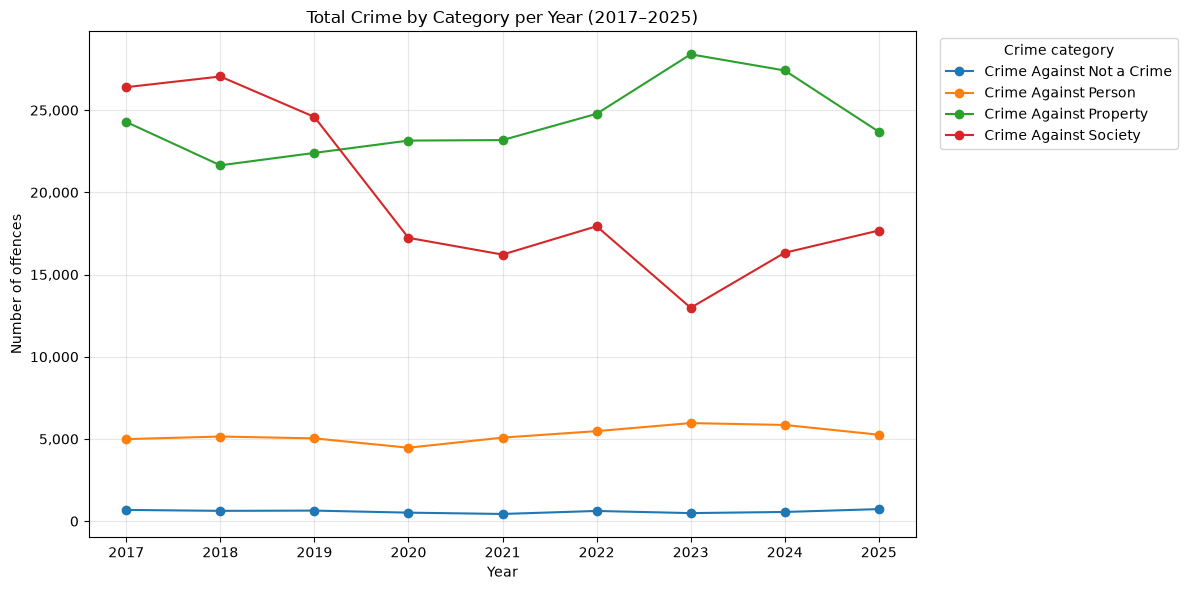

In [23]:
fig, ax = plt.subplots(figsize=(12, 6))
yearly_cat.drop("Total").plot(ax=ax, marker="o")
 
ax.set_title("Total Crime by Category per Year (2017–2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of offences")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.legend(title="Crime category", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)
 
plt.tight_layout()
plt.show()

**Graph Finding:** Crime Against Society was the largest category in 2017–2019, but dropped steeply in 2020 (approx 17,000 offences) and reached its lowest point in 2023 (13,000 offences) before partly recovering. Crime Against Property overtook it from 2020 onwards and peaked in 2023 (approx 28,000 offences). Crime Against Person stayed relatively stable at between 4,467 and 5,966 offences per year.

### Visualisation 2

**Aim:** Comparing the overall % change (and absolute change) in each crime category between 2017 and 2025.

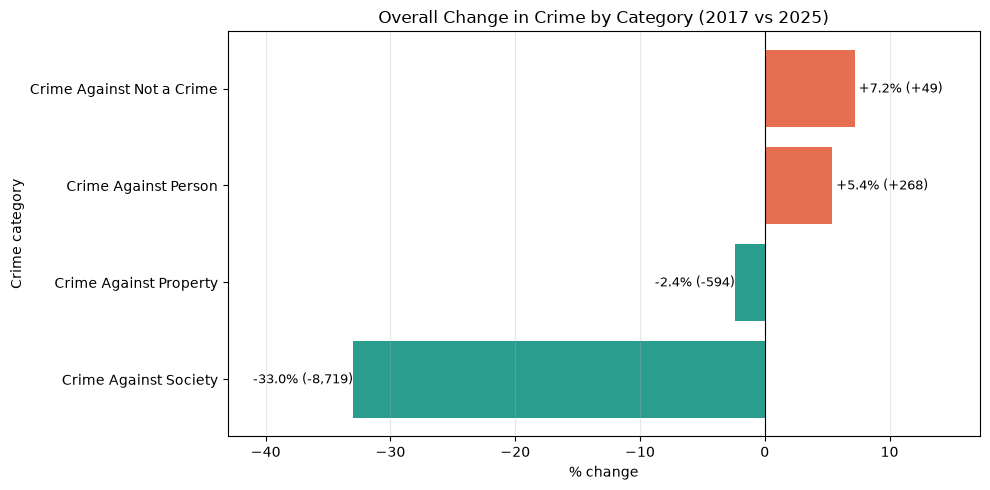

In [24]:
plot_df = dfichange.drop("Total")
colors = ["#2a9d8f" if v < 0 else "#e76f51" for v in plot_df["% change"]]
 
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_df.index, plot_df["% change"], color=colors)
 
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Overall Change in Crime by Category (2017 vs 2025)")
ax.set_xlabel("% change")
ax.set_ylabel("Crime category")
 
for bar, pct, abs_chg in zip(bars, plot_df["% change"], plot_df["Absolute change"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f" {pct:+.1f}% ({int(abs_chg):+,})",
            va="center", ha="left" if pct >= 0 else "right", fontsize=9)
 
ax.margins(x=0.25)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Finding:** Crime Against Society shows the largest decrease (−33.0%, −8,719 offences). Crime Against Property decreased only slightly (−2.4%), while Crime Against Person (+5.4%) and Not a Crime (+7.2%) increased.

### Hypothesis Testing

**Method:** We used a chi-square test of independence on the Year × Crime Name 1 table (2017–2025), excluding “Crime Against Not a Crime”, to test H0 and H1 stated above. We reported Cramér’s V to show how much the category mix differed, since even small differences can be statistically significant in a large dataset.

In [25]:
# 2017–2025, without "Not a Crime"
htest_df = dfi_full[dfi_full["Crime Name 1"] != "Crime Against Not a Crime"]

ct = pd.crosstab(htest_df["Year"], htest_df["Crime Name 1"])

chi2, p, dof, _ = stats.chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print(f"Chi-square = {chi2:,.1f}, df = {dof}, p = {p:.4g}, Cramér's V = {cramers_v:.3f}")

Chi-square = 9,562.3, df = 16, p = 0, Cramér's V = 0.104


**Result:** χ² = 9,562.3, df = 16, p < 0.001, Cramér's V = 0.104.

**Decision:** Reject H0 (p < 0.05).

**Interpretation:** The mix of crime categories changed significantly across the years. However, Cramér's V ≈ 0.10 indicates a **small** effect: the overall category composition shifted, but not dramatically.

### Conclusion

**Conclusion:** Recorded crime fell by 16.0% between 2017 and 2025, mainly because Crime Against Society dropped by a third. Crime Against Property became the dominant category from 2020 onwards, and Crime Against Person increased slightly. The chi-square test confirmed that the category mix changed significantly across the years (χ² = 9,562.3, p < 0.001), but the effect size was small (Cramér's V = 0.104), so the composition of crime shifted only slightly rather than dramatically.

**Limitations:**
- Counts are offence rows, not unique incidents; one incident can contain several offences.
- Recorded crime reflects reporting and policing activity, not necessarily actual crime levels.
- Only full years 2017–2025 are analysed; "Crime Against Not a Crime" is excluded from the test.

## RQ2 — Concentration of Motor Vehicle Thefts by District and Place

**Research Question:** In which police districts and places are recorded motor vehicle thefts most concentrated, and do these concentrations change over time?

**Aim:** Identify the districts and place types with the highest share of motor vehicle thefts (MVT) and test whether the share of thefts across place types changed between 2017 and 2025.

**Method:** Filter `Crime Name 2 == "Motor Vehicle Theft"` for 2017–2025. Use `Police District Name`, `Place` and `Year`. Calculate share and cumulative share of thefts, then apply a chi-square test of independence (Year × Place) with Cramér's V.

**H0:** The place where motor vehicle thefts happen does not depend on the year (2017 to 2025).

**H1:** The place where motor vehicle thefts happen depends on the year (2017 to 2025).

### Data Preparation

In [49]:
dfi["Year"] = dfi["Start Date/Time"].dt.year
dfimvt = dfi[(dfi["Crime Name 2"] == "Motor Vehicle Theft") & dfi["Year"].between(2017, 2025)].copy()

# Top 10 places, the rest grouped as 'Other' (used in Visualisation 2 and the chi-square test)
top_places = dfimvt["Place"].value_counts().head(10).index
dfimvt["Place Group"] = dfimvt["Place"].where(dfimvt["Place"].isin(top_places), "Other")

print("MVT (2017-2025):", dfimvt.shape)

MVT (2017-2025): (15521, 35)


### Findings

In [50]:
def dficoncen(col, top=10):
   th = dfimvt[col].value_counts().to_frame("Thefts")
   th["% of total"] = th["Thefts"] / th["Thefts"].sum() * 100

   th["Cumulative %"] = th["% of total"].cumsum().round(2)
   return th.head(top)

display(dficoncen("Police District Name"))
display(dficoncen("Beat"))
display(dficoncen("Place"))


,Thefts,% of total,Cumulative %
Police District Name,,,
SILVER SPRING,4830,31.270232,31.27
WHEATON,2847,18.431956,49.70
MONTGOMERY VILLAGE,2423,15.686909,65.39
BETHESDA,1897,12.281497,77.67
ROCKVILLE,1554,10.060857,87.73
GERMANTOWN,1400,9.063835,96.80
TAKOMA PARK,493,3.191765,99.99
OTHER,2,0.012948,100.00


,Thefts,% of total,Cumulative %
Beat,,,
3G1,1289,8.304877,8.30
3I2,1099,7.080729,15.39
3I1,1083,6.977643,22.36
4K1,664,4.278075,26.64
4L1,601,3.872173,30.51
5N1,495,3.189227,33.70
6R2,476,3.066813,36.77
4L2,471,3.034598,39.80
3H2,464,2.989498,42.79


,Thefts,% of total,Cumulative %
Place,,,
Parking Lot - Residential,4896,31.544359,31.54
Street - Residential,3539,22.801366,54.35
Residence - Driveway,1521,9.799626,64.15
Parking Lot - Commercial,1061,6.835900,70.98
Parking Garage - Residential,597,3.846402,74.83
Street - Commercial,444,2.860640,77.69
Auto Dealership,379,2.441853,80.13
Street - In vehicle,335,2.158366,82.29
Residence - Single Family,330,2.126152,84.41


In [51]:
place_totals = dfimvt["Place"].value_counts()
print("Highest theft place:", place_totals.idxmax())
print("Total thefts:", place_totals.max())
print(f"Share of all thefts: {place_totals.max() / place_totals.sum() * 100:.1f}%")

place_totals.head(50)

Highest theft place: Parking Lot - Residential
Total thefts: 4896
Share of all thefts: 31.5%


Place
Parking Lot - Residential             4896
Street - Residential                  3539
Residence - Driveway                  1521
Parking Lot - Commercial              1061
Parking Garage - Residential           597
Street - Commercial                    444
Auto Dealership                        379
Street - In vehicle                    335
Residence - Single Family              330
Street - Other                         284
Residence - Apartment/Condo            260
Parking Garage - County                185
Parking Lot - Other                    170
Parking Garage - Commercial            153
Gas Station                            141
Residence -Townhouse/Duplex            135
Auto Repair                             78
Residence - Yard                        73
Retail - Other                          73
Other/Unknown                           72
Residence - Garage                      72
Hotel/Motel/Etc.                        49
Parking Garage - Other                  48
Parki

**Finding:** There were 15,521 motor vehicle thefts between 2017 and 2025. Thefts are concentrated in a few districts: **Silver Spring** recorded 4,830 thefts (31.3%), followed by Wheaton (18.4%) and Montgomery Village (15.7%); together these three districts account for 65.4% of all thefts. By place, **Parking Lot - Residential** was the most common location with 4,896 thefts (31.5%), followed by Street - Residential (22.8%) and Residence - Driveway (9.8%); the top three places account for 64.2% of thefts.

**Decision:** Motor vehicle theft is strongly concentrated in residential parking and street locations and in the south-east districts. How these concentrations change over time is examined visually below and then tested formally with a chi-square test.

### Visualisation 1

**Aim:** Show each police district's share of motor vehicle thefts per year to see whether the concentration shifts over time.

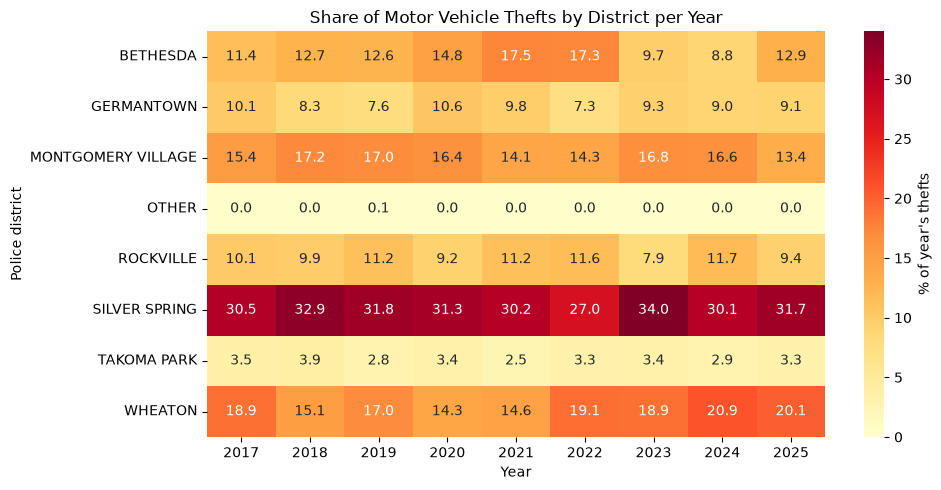

Police District Name,BETHESDA,GERMANTOWN,MONTGOMERY VILLAGE,OTHER,ROCKVILLE,SILVER SPRING,TAKOMA PARK,WHEATON
Year,,,,,,,,
2017,104,92,140,0,92,277,32,172
2018,105,69,142,0,82,272,32,125
2019,113,68,153,1,101,286,25,153
2020,172,124,191,0,107,365,40,167
2021,251,140,202,0,161,433,36,209
2022,259,109,215,0,174,405,50,287
2023,335,321,581,1,273,1174,118,653
2024,259,266,489,0,346,886,84,616
2025,299,211,310,0,218,732,76,465


In [52]:
dist_year = pd.crosstab(dfimvt["Year"], dfimvt["Police District Name"])
dist_share = dist_year.div(dist_year.sum(axis=1), axis=0).mul(100).round(1)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(dist_share.T, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "% of year's thefts"})
ax.set_title("Share of Motor Vehicle Thefts by District per Year")
ax.set_xlabel("Year")
ax.set_ylabel("Police district")
plt.tight_layout()
plt.show()

dist_year 


**Finding:** Silver Spring had the highest share of thefts in every year (between 27.0% and 34.0%), followed by Wheaton and Montgomery Village. The number of thefts rose sharply after 2020 and peaked in 2023 (3,456 thefts, compared with 909 in 2017), with Silver Spring alone recording 1,174 thefts in 2023. The ranking of districts stayed broadly stable over time.

### Visualisation 2

**Aim:** Show each place type's share of motor vehicle thefts per year (top 10 places, all others grouped as "Other") to see whether theft locations change over time.

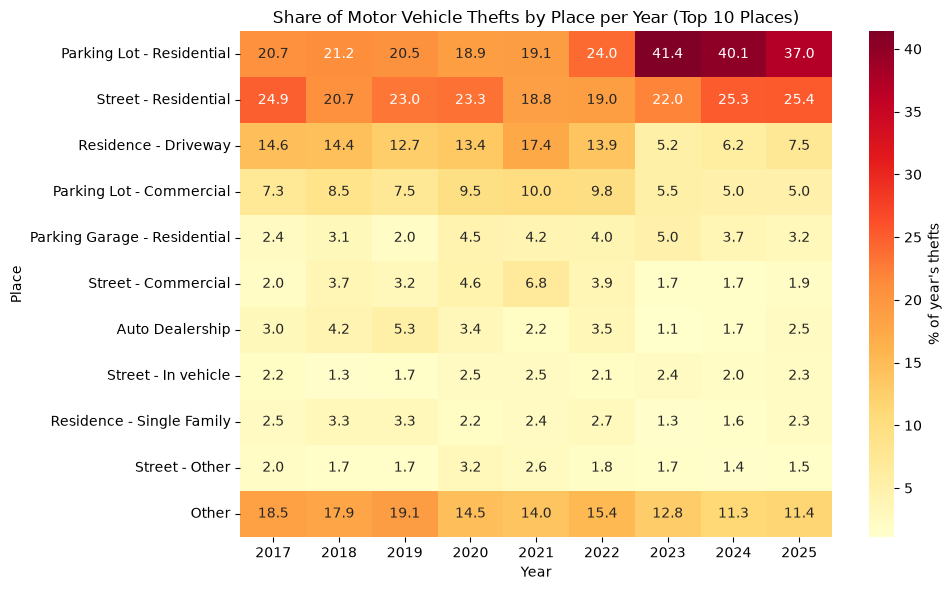

Place Group,Parking Lot - Residential,Street - Residential,Residence - Driveway,Parking Lot - Commercial,Parking Garage - Residential,Street - Commercial,Auto Dealership,Street - In vehicle,Residence - Single Family,Street - Other,Other
Year,,,,,,,,,,,
2017,188,226,133,66,22,18,27,20,23,18,168
2018,175,171,119,70,26,31,35,11,27,14,148
2019,185,207,114,68,18,29,48,15,30,15,172
2020,221,272,156,111,53,54,40,29,26,37,169
2021,273,269,250,144,60,97,31,36,35,37,201
2022,360,285,209,147,60,59,52,31,41,27,231
2023,1442,766,183,191,173,60,37,82,47,59,446
2024,1192,752,183,149,111,51,51,58,47,42,336
2025,860,591,174,115,74,45,58,53,54,35,264


In [53]:
place_year = pd.crosstab(dfimvt["Year"], dfimvt["Place Group"])
place_order = list(top_places) + ["Other"]
place_share = place_year.div(place_year.sum(axis=1), axis=0).mul(100).round(1)[place_order]
 
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(place_share.T, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "% of year's thefts"})
ax.set_title("Share of Motor Vehicle Thefts by Place per Year (Top 10 Places)")
ax.set_xlabel("Year")
ax.set_ylabel("Place")
plt.tight_layout()
plt.show()
 
place_year[place_order]

**Finding:** Parking Lot - Residential grew from 20.7% of thefts in 2017 to 41.4% in 2023 and 37.0% in 2025, becoming the dominant theft location. Street - Residential remained stable at around a quarter of thefts (24.9% in 2017, 25.4% in 2025), while Residence - Driveway fell from 14.6% to 7.5%. Whether this shift in place shares is statistically significant is tested in the Hypothesis Testing section.

### Hypothesis Testing

**Method:** Chi-square test of independence on the Year × Place table to test H0 and H1 stated above. Places outside the top 10 are grouped as "Other" (in Data Preparation) so that expected cell counts stay large enough; this is the same table shown in Visualisation 2. Cramér's V is reported as the effect size.

In [54]:
ct_place = pd.crosstab(dfimvt["Year"], dfimvt["Place Group"])

chi2, p, dof, expected = stats.chi2_contingency(ct_place)
cramers_v = np.sqrt(chi2 / (ct_place.values.sum() * (min(ct_place.shape) - 1)))
print(f"Chi-square = {chi2:,.1f}, df = {dof}, p = {p:.4g}, Cramér's V = {cramers_v:.3f}")
print(f"Cells with expected count < 5: {(expected < 5).mean():.1%}")

Chi-square = 1,267.7, df = 80, p = 5.293e-213, Cramér's V = 0.101
Cells with expected count < 5: 0.0%


**Result:** χ² = 1,267.7, df = 80, p < 0.001, Cramér's V = 0.101. No cells had an expected count below 5.

**Decision:** Reject H0 (p < 0.05).

**Interpretation:** The distribution of motor vehicle thefts across place types differed significantly across the years 2017–2025. The effect size is small (V ≈ 0.10), meaning the main theft locations stayed the same but their relative shares shifted.

### Conclusion

**Conclusion:** Motor vehicle thefts are highly concentrated: three districts (Silver Spring, Wheaton and Montgomery Village) account for 65.4% of thefts, and three residential place types account for 64.2%. Thefts more than tripled between 2017 and the 2023 peak. The chi-square test showed that the place distribution changed significantly over time (χ² = 1,267.7, p < 0.001, V = 0.101), mainly because residential parking lots became a much larger share of thefts while driveways became smaller. The effect is small, so the overall pattern of concentration remained similar.

**Limitations:**
- Counts are offence rows, not unique incidents.
- `Place` categories are recorded by officers and may be applied inconsistently.
- Districts differ in size and population, so raw counts are not rates.

## RQ3 - Highest-Offence Streets by Reporting Agency

**Research Question:** How do the streets with the highest recorded offence counts differ across reporting agencies?

**Aim:** Identify each agency's top 5 streets by offence count and test whether agencies differ in how concentrated their offences are on those streets.

**Method:** Use `Agency`, `Street Name` and `Street Type`. Build a combined `Street` field, count offences per Agency × Street, then apply a chi-square test (Agency × Top-5 vs Other streets) with Cramér's V.

**H0:** The proportion of offences occurring on each agency's top 5 streets is the same for all agencies.

**H1:** The proportion of offences occurring on the top 5 streets differs between agencies.

### Data Preparation

In [35]:
dfstr = dfi.dropna(subset=["Street Name"]).copy()
dfstr["Street"] = (dfstr["Street Name"].str.strip() + " " +  dfstr["Street Type"].fillna("")).str.strip()
dfstr["Agency"].value_counts()

Agency
MCPD    433032
RCPD     28773
GPD      28449
TPPD     14760
MCFM      1234
MCSO       156
OTHR         4
P            3
Name: count, dtype: int64

In [36]:
# Offences per street for each agency
street_counts = (dfstr.groupby(["Agency", "Street"]).size()
                 .rename("Offences").reset_index())
street_counts.head()

,Agency,Street,Offences
0,GPD,124-S270,2
1,GPD,1ST ST,1
2,GPD,270 HWY,2
3,GPD,370-N355 RMP,1
4,GPD,AIRCRAFT DR,1


### Findings

In [37]:
top_streets = (
    dfstr.groupby(["Agency", "Street"]).size().rename("Offences").reset_index()
       .sort_values(["Agency", "Offences"], ascending=[True, False])
       .groupby("Agency").head(5)
)
 
# Each street's share of its agency's offences
top_streets["% of agency"] = (top_streets["Offences"]
                              / top_streets["Agency"].map(dfstr["Agency"].value_counts()) * 100).round(1)
top_streets

,Agency,Street,Offences,% of agency
306,GPD,FREDERICK AVE,3479,12.2
710,GPD,RUSSELL AVE,1765,6.2
814,GPD,SUMMIT AVE,1290,4.5
229,GPD,DIAMOND AVE,1173,4.1
349,GPD,GRAND CORNER AVE,1018,3.6
1233,MCFM,GEORGIA AVE,38,3.1
1456,MCFM,OAK LEAF DR,18,1.5
1652,MCFM,UNIVERSITY BLV,18,1.5
1440,MCFM,NEW HAMPSHIRE AVE,13,1.1
1219,MCFM,FREDERICK AVE,12,1.0


In [38]:
top_streets.groupby("Street")["Agency"].apply(list).sort_values(key=lambda s: s.str.len(), ascending=False)

Street
NEW HAMPSHIRE AVE    [MCFM, MCPD, TPPD]
VEIRS MILL RD           [MCPD, P, RCPD]
UNIVERSITY BLV       [MCFM, MCPD, TPPD]
FREDERICK AVE               [GPD, MCFM]
GEORGIA AVE                [MCFM, MCPD]
MUNCASTER MILL RD             [MCSO, P]
CARROLL AVE                      [TPPD]
DIAMOND AVE                       [GPD]
EDISON PARK DR                   [OTHR]
GRAND CORNER AVE                  [GPD]
FREDERICK RD                     [MCPD]
FLOWER AVE                       [TPPD]
FLOWER HILL WAY                  [MCSO]
MIDCOUNTY HWY                    [MCSO]
MARYLAND AVE                     [RCPD]
HUNGERFORD DR                    [RCPD]
MAPLE AVE                        [TPPD]
OAK LEAF DR                      [MCFM]
MONTGOMERY AVE                   [RCPD]
PARK MILL DR                     [MCSO]
ROCKVILLE PIK                    [RCPD]
SUGAR NOTCH CIR                     [P]
RUSSELL AVE                       [GPD]
SUMMIT AVE                        [GPD]
WASHINGTON ST                    

In [39]:
stats_table = street_counts.groupby("Agency")["Offences"].describe().round(1)
stats_table = stats_table.rename(columns={"count": "No. of streets"})
stats_table["Total offences"] = street_counts.groupby("Agency")["Offences"].sum()
stats_table = stats_table.sort_values("Total offences", ascending=False)
stats_table

,No. of streets,mean,std,min,25%,50%,75%,max,Total offences
Agency,,,,,,,,,
MCPD,10272.0,42.2,315.5,1.0,4.0,9.0,22.0,20688.0,433032
RCPD,755.0,38.1,174.9,1.0,2.0,5.0,18.0,3686.0,28773
GPD,959.0,29.7,159.4,1.0,1.0,3.0,10.0,3479.0,28449
TPPD,177.0,83.4,316.2,1.0,4.0,20.0,59.0,3327.0,14760
MCFM,752.0,1.6,2.1,1.0,1.0,1.0,1.0,38.0,1234
MCSO,37.0,4.2,12.4,1.0,1.0,1.0,2.0,73.0,156
OTHR,1.0,4.0,NaN,4.0,4.0,4.0,4.0,4.0,4
P,3.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,3


In [40]:
conc = pd.DataFrame({
    "Top 5": top_streets.groupby("Agency")["Offences"].sum(),
    "Total": street_counts.groupby("Agency")["Offences"].sum()
})
conc["Other"] = conc["Total"] - conc["Top 5"]
conc["Top 5 %"] = (conc["Top 5"] / conc["Total"] * 100).round(1)

# Exclude agencies with too few offences for a valid chi-square test
conc = conc[conc["Total"] >= 100]
conc = conc.sort_values("Top 5 %", ascending=False)
conc

,Top 5,Total,Other,Top 5 %
Agency,,,,
MCSO,116,156,40,74.4
TPPD,8176,14760,6584,55.4
GPD,8725,28449,19724,30.7
RCPD,8388,28773,20385,29.2
MCPD,54040,433032,378992,12.5
MCFM,99,1234,1135,8.0


**Finding:** Each agency's top streets are different and largely reflect its jurisdiction. MCPD's top street is Georgia Ave (20,688 offences, 4.8% of its offences), RCPD's is Rockville Pike (12.8%), GPD's is Frederick Ave (12.2%), TPPD's is New Hampshire Ave (22.5%) and MCSO's is Muncaster Mill Rd (46.8%). A few major roads appear in the top five of more than one agency: New Hampshire Ave and University Blvd (MCFM, MCPD, TPPD), Veirs Mill Rd (MCPD, RCPD, P), Georgia Ave (MCFM, MCPD) and Frederick Ave (GPD, MCFM). MCPD covers by far the most streets (10,272) and offences (433,032), while TPPD has the highest average offences per street (83.4).

**Decision:** Agencies appear to differ in how concentrated their offences are on a few streets. This is examined visually below and then tested formally with a chi-square test on the share of offences on each agency's top 5 streets.

### Visualisation 1

**Aim:** Show the share of each agency's offences that occur on every top street, highlighting where agencies overlap or differ.

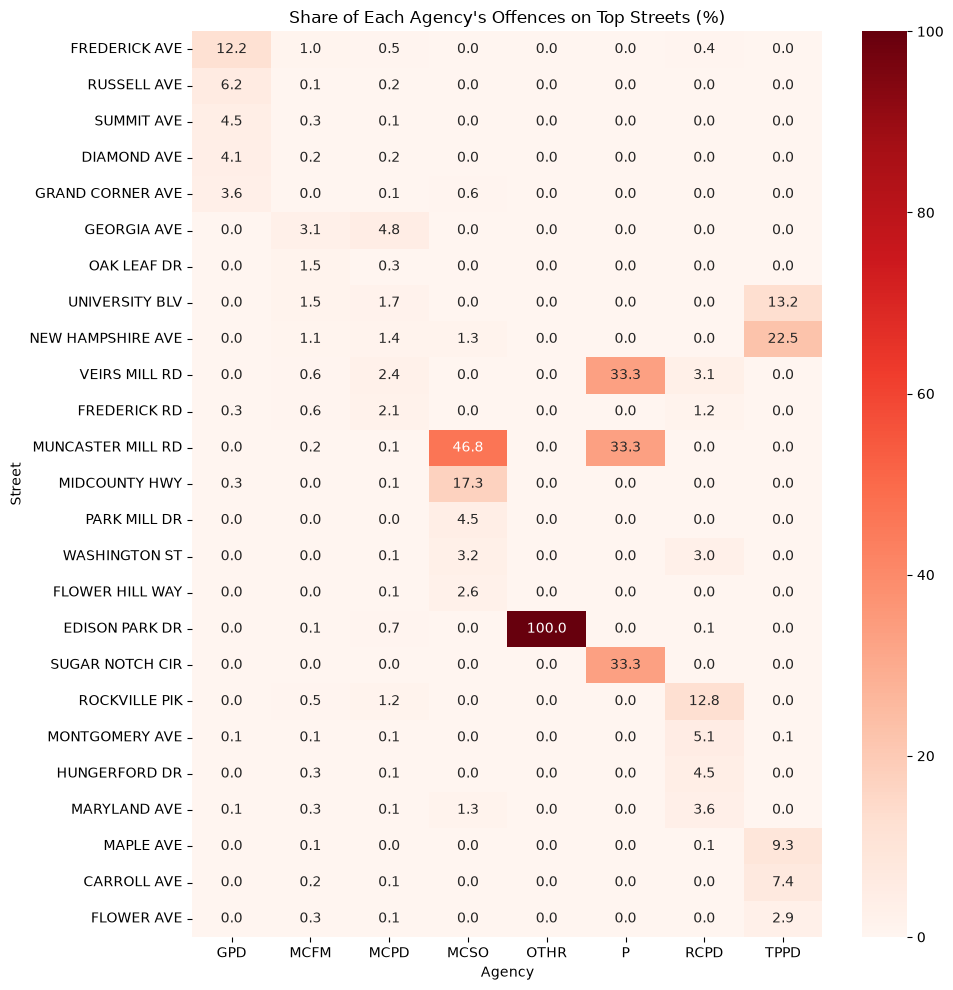

In [41]:
streets = top_streets["Street"].unique()
share = pd.crosstab(dfstr["Street"], dfstr["Agency"], normalize="columns").loc[streets] * 100
 
plt.figure(figsize=(10, 10))
sns.heatmap(share, annot=True, fmt=".1f", cmap="Reds")
plt.title("Share of Each Agency's Offences on Top Streets (%)")
plt.xlabel("Agency")
plt.ylabel("Street")
plt.tight_layout()
plt.show()

**Finding:** Most top streets are important to only one agency, showing that hotspot streets are largely agency-specific. The darkest cells are MCSO on Muncaster Mill Rd (46.8%), TPPD on New Hampshire Ave (22.5%) and University Blvd (13.2%), RCPD on Rockville Pike (12.8%) and GPD on Frederick Ave (12.2%). MCPD's top streets each account for less than 5% of its offences.

### Visualisation 2

**Aim:** Compare how concentrated each agency's offences are on its top 5 streets (this is the comparison tested formally in the Hypothesis Testing section).

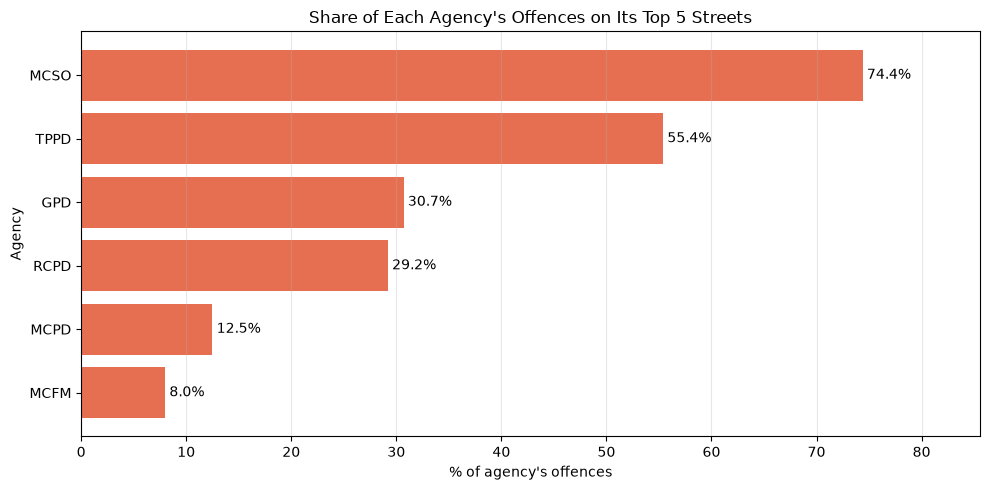

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(conc.index, conc["Top 5 %"], color="#e76f51")
ax.invert_yaxis()

ax.set_title("Share of Each Agency's Offences on Its Top 5 Streets")
ax.set_xlabel("% of agency's offences")
ax.set_ylabel("Agency")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Finding:** Offence concentration varies widely between agencies. Smaller agencies with compact jurisdictions (MCSO 74.4%, TPPD 55.4%) have most of their offences on a few streets, the city police departments (GPD 30.7%, RCPD 29.2%) are moderately concentrated, and the county-wide agencies (MCPD 12.5%, MCFM 8.0%) are spread across many streets.

### Hypothesis Testing

**Method:** Chi-square test of independence on the Agency × (Top 5 streets vs Other streets) table built in the Findings section, with Cramér's V, to test H0 and H1 stated above. Agencies with fewer than 100 recorded offences (P and OTHR) are excluded so that expected cell counts are at least 5. Pairwise two-proportion z-tests with Holm correction identify which agencies differ.

In [43]:
chi2, p, dof, expected = stats.chi2_contingency(conc[["Top 5", "Other"]])
cramers_v = np.sqrt(chi2 / conc["Total"].sum())   # min(rows, cols) - 1 = 1
print(f"Chi-square = {chi2:,.1f}, df = {dof}, p = {p:.4g}, Cramér's V = {cramers_v:.3f}")
print("Any expected count < 5:", (expected < 5).any())

Chi-square = 30,163.3, df = 5, p = 0, Cramér's V = 0.244
Any expected count < 5: False


In [44]:
from itertools import combinations

pairs, pvals = [], []
for a, b in combinations(conc.index, 2):
    _, pv = proportions_ztest(conc.loc[[a, b], "Top 5"], conc.loc[[a, b], "Total"])
    pairs.append(f"{a} vs {b}")
    pvals.append(pv)

reject, p_adj, _, _ = multipletests(pvals, method="holm")
pd.DataFrame({"Pair": pairs, "p (Holm)": p_adj, "Significant": reject}).sort_values("p (Holm)")

,Pair,p (Holm),Significant
6,TPPD vs RCPD,0.000000e+00,True
7,TPPD vs MCPD,0.000000e+00,True
5,TPPD vs GPD,0.000000e+00,True
10,GPD vs MCPD,0.000000e+00,True
12,RCPD vs MCPD,0.000000e+00,True
8,TPPD vs MCFM,1.479730e-223,True
3,MCSO vs MCPD,8.949123e-120,True
4,MCSO vs MCFM,1.808032e-102,True
11,GPD vs MCFM,2.919271e-64,True
13,RCPD vs MCFM,8.248534e-58,True


**Result:** χ² = 30,163.3, df = 5, p < 0.001, Cramér's V = 0.244. No cells had an expected count below 5. All 15 pairwise comparisons were significant after Holm correction.

**Decision:** Reject H0 (p < 0.05).

**Interpretation:** The proportion of offences on the top 5 streets differs significantly between agencies, with a small-to-medium effect size. The top 5 streets account for 74.4% of MCSO offences and 55.4% of TPPD offences, compared with 30.7% for GPD, 29.2% for RCPD, 12.5% for MCPD and 8.0% for MCFM.

### Conclusion

**Conclusion:** The streets with the highest offence counts differ clearly across agencies and mostly reflect each agency's jurisdiction, although major corridors such as New Hampshire Ave, University Blvd, Veirs Mill Rd and Georgia Ave are hotspots for several agencies. The chi-square test showed that the concentration of offences on the top 5 streets differs significantly between agencies (χ² = 30,163.3, p < 0.001, V = 0.244). Smaller agencies such as MCSO and TPPD have offences concentrated on a few streets, while county-wide MCPD and MCFM have offences spread across many streets.

**Limitations:**
- Agencies police different jurisdictions, so differences in top streets partly reflect geography.
- Counts are offence rows, not unique incidents.
- Street names are combined from `Street Name` and `Street Type`; inconsistent spelling may split one street into several.